In [1]:
import os
import sys
import json
from pathlib import Path


In [1]:
PROJECT_ROOT = Path(os.environ.get("SAFETY_WATCH_PROJECT_ROOT", "/workspace"))
RUNTIME_ROOT = Path(os.environ.get("SAFETY_WATCH_RUNTIME_ROOT", "/runtime"))
sys.path.insert(0, str(PROJECT_ROOT / "src"))


In [1]:
from safety_watch.classifier import TrainConfig, train_guardrail, export_run, load_guardrail, evaluate_final
from safety_watch.classifier.runtime import check_runtime


In [1]:
RUN_MODEL_SELECTION = True
FREEZE_MODEL = False
RUN_FINAL_TEST = False


In [1]:
config = TrainConfig(runtime_root=RUNTIME_ROOT, project_root=PROJECT_ROOT, search=RUN_MODEL_SELECTION)
config.model.update(C=1.0, class_weight=None)


In [1]:
print(json.dumps(check_runtime(), indent=2))


{
  "python": "3.12.15",
  "architecture": "s390x",
  "interpreter": "/opt/venv/bin/python3",
  "sklearn": "1.9.0",
  "numpy": "2.0.2",
  "scipy": "1.13.1",
  "pandas": "3.0.6",
  "joblib": "1.6.0"
}


In [2]:
result = train_guardrail(config)


In [2]:
print("Private development run:", result.run_dir)
print(json.dumps(result.card["split_summary"], indent=2))


Private development run: /runtime/results/classifier-runs/train-20261017T081907Z-9b5b7dfb
{
  "cross_boundary_excluded": 196,
  "within_training_excluded": 95,
  "eligible": 4791,
  "fit": 3832,
  "validation": 959,
  "partitions_sha256": "cd5e3febd5e3025cf905214a1369344f5f22b9613fe35a2c577842eacf037c6d"
}


In [3]:
print("Selected model settings:")
print(json.dumps(result.card["configuration"]["model"], indent=2))


Selected model settings:
{
  "analyzer": "char",
  "ngram_range": [
    3,
    5
  ],
  "lowercase": true,
  "min_df": 2,
  "max_features": 100000,
  "sublinear_tf": true,
  "norm": "l2",
  "solver": "liblinear",
  "C": 100.0,
  "class_weight": "balanced",
  "max_iter": 1000
}


In [3]:
print("Selection evidence:")
print(json.dumps(result.card["model_selection"], indent=2))


Selection evidence:
{
  "enabled": true,
  "scope": "fitting partition only",
  "folds": 3,
  "candidate_count": 12,
  "classifier_fits": 36,
  "ranking": "pooled human recall at <=5% fold FPR, then mean AP, smaller C, no weighting",
  "selected_parameters": {
    "C": 100.0,
    "class_weight": "balanced"
  },
  "selected_cv_recall": 0.6787003610108303,
  "selected_cv_average_precision": 0.7420703559159537,
  "search_seconds": 7.2358425479906145,
  "search_artifact_sha256": "d01d5c7419938be540d739caa26e339837dcac402446d9a4dbbac541c72318c5"
}


In [3]:
print("Fitting runtime:")
print(json.dumps(result.card["runtime"], indent=2))


Fitting runtime:
{
  "training_seconds": 1.3689184120012214,
  "feature_count": 85327,
  "solver_iterations": [
    8
  ],
  "process_peak_rss_mib": 271.87109375,
  "validation_scoring_seconds": 0.22882702699280344,
  "validation_records": 959,
  "model_bytes": 3622800
}


In [4]:
import pandas as pd


In [4]:
print(json.dumps(result.card["threshold"], indent=2))
print(pd.DataFrame(result.card["validation_metrics"]).T.to_string())


{
  "threshold": 0.3590141404799981,
  "decision": "score >= threshold",
  "target_fpr": 0.05,
  "benign_human_validation_records": 457,
  "benign_human_refused": 22,
  "observed_fpr": 0.04814004376367615
}
                               records  benign  unsafe     tn    fp    fn    tp  precision    recall        f1       fpr  false_negative_rate  average_precision
human_annotated                  527.0   457.0    70.0  435.0  22.0  18.0  52.0   0.702703  0.742857  0.722222  0.048140             0.257143           0.788108
full_validation_supplementary    959.0   889.0    70.0  863.0  26.0  18.0  52.0   0.666667  0.742857  0.702703  0.029246             0.257143           0.764159


In [5]:
import numpy as np
import matplotlib.pyplot as plt


In [5]:
validation = result.split.validation
human_mask = validation["human_annotation"].to_numpy(dtype=bool)
labels = validation["unsafe"].to_numpy(dtype=int)
validation_scores = result.scores
threshold = result.threshold
validation_metrics = result.card["validation_metrics"]
run_dir = result.run_dir


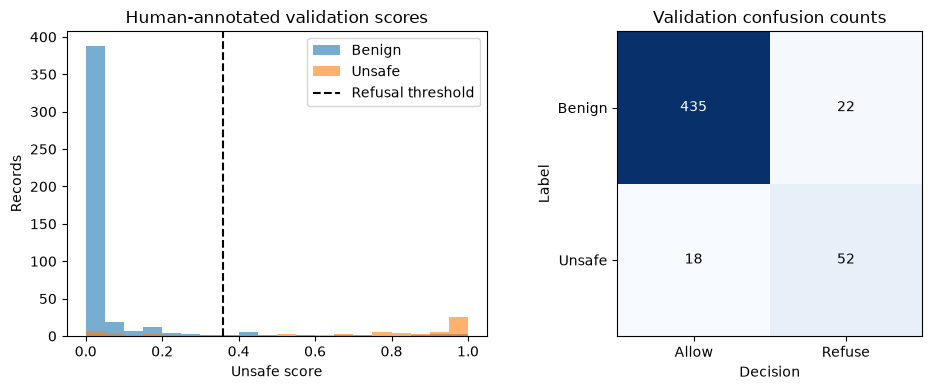

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for value, name in ((0, "Benign"), (1, "Unsafe")):
    mask = human_mask & (labels == value)
    axes[0].hist(validation_scores[mask], bins=np.linspace(0, 1, 21), alpha=0.6, label=name)
axes[0].axvline(threshold, color="black", linestyle="--", label="Refusal threshold")
axes[0].set(xlabel="Unsafe score", ylabel="Records", title="Human-annotated validation scores")
axes[0].legend()
m = validation_metrics["human_annotated"]
axes[1].imshow([[m["tn"], m["fp"]], [m["fn"], m["tp"]]], cmap="Blues")
for row, values in enumerate(((m["tn"], m["fp"]), (m["fn"], m["tp"]))):
    for column, value in enumerate(values):
        axes[1].text(column, row, str(value), ha="center", va="center",
                     color="white" if value > max(m["tn"], m["fp"], m["fn"], m["tp"]) / 2 else "black")
axes[1].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["Allow", "Refuse"],
            yticklabels=["Benign", "Unsafe"], xlabel="Decision", ylabel="Label", title="Validation confusion counts")
fig.tight_layout()
fig.savefig(run_dir / "validation-summary.png", dpi=150)
plt.show()
plt.close(fig)


In [6]:
print(json.dumps(result.summary, indent=2))


{
  "run_id": "20261017T081907Z-9b5b7dfb",
  "results_directory": "/runtime/results/classifier-runs/train-20261017T081907Z-9b5b7dfb",
  "model_sha256": "16cc50b1e16df16f937cc89c64eea164ed59f70275ccad09cc9303af1e9f2fce",
  "partition_sha256": "cd5e3febd5e3025cf905214a1369344f5f22b9613fe35a2c577842eacf037c6d",
  "threshold": 0.3590141404799981,
  "human_validation": {
    "records": 527,
    "benign": 457,
    "unsafe": 70,
    "tn": 435,
    "fp": 22,
    "fn": 18,
    "tp": 52,
    "precision": 0.7027027027027027,
    "recall": 0.7428571428571429,
    "f1": 0.7222222222222222,
    "fpr": 0.04814004376367615,
    "false_negative_rate": 0.2571428571428571,
    "average_precision": 0.7881080893363139
  },
  "final_test_requested": false,
  "freeze_requested": false,
  "evidence": {
    "records": 5,
    "head": "e9513e3708ae2ae3b92ba6d7853b6bd901ce2162ba3505c949829c477821382b"
  }
}


In [6]:
if (RUNTIME_ROOT / "models/guardrail.freeze.json").is_file():
    saved = load_guardrail(RUNTIME_ROOT / "models")
    print("Saved artifact:", json.dumps({
        "model_sha256": saved.digest, "threshold": saved.threshold,
        "source_run_id": saved.card["source_run_id"],
    }, indent=2))
else:
    print("No saved artifact yet; use the export script after reviewing a verified run.")


Saved artifact: {
  "model_sha256": "16cc50b1e16df16f937cc89c64eea164ed59f70275ccad09cc9303af1e9f2fce",
  "threshold": 0.3590141404799981,
  "source_run_id": "20261017T061152Z-a17252db"
}


In [7]:
if FREEZE_MODEL:
    print(json.dumps(export_run(result.run_dir, RUNTIME_ROOT), indent=2))
else:
    print("Export disabled in this notebook; the existing saved model remains unchanged.")


Export disabled in this notebook; the existing saved model remains unchanged.


In [8]:
if RUN_FINAL_TEST:
    print(json.dumps(evaluate_final(RUNTIME_ROOT, confirmed=True), indent=2))
else:
    print("Official-test scoring remains disabled.")


Official-test scoring remains disabled.
